# H A A S Hettiarachchi (IT25104064)

MRI Image Enhancement using CLAHE


## Part 1 - Install libraries

In [1]:
%pip -q install kagglehub opencv-python-headless scikit-image scikit-learn

## Part 2 - Imports/folders

In [2]:
from pathlib import Path
import os, zipfile, shutil, hashlib, random, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, ImageEnhance

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

BASE = Path('/content') if Path('/content').exists() else Path.cwd()
WORK = BASE / 'brain_tumor_preprocessing'
DATA_DIR = WORK / 'dataset'
RESULTS = WORK / 'results'
DATA_DIR.mkdir(parents=True, exist_ok=True)
RESULTS.mkdir(parents=True, exist_ok=True)

IMG_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'}

## Part 3 - Download the assigned dataset from KaggleHub

In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("sartajbhuvaji/brain-tumor-classification-mri")

print("Path to dataset files:", path)

DATASET_ROOT = Path(path)
TRAIN_DIR = DATASET_ROOT / "Training"
TEST_DIR = DATASET_ROOT / "Testing"

assert TRAIN_DIR.exists(), f"Training folder not found inside: {DATASET_ROOT}"
assert TEST_DIR.exists(), f"Testing folder not found inside: {DATASET_ROOT}"

print("Training folder:", TRAIN_DIR)
print("Testing folder :", TEST_DIR)


Using Colab cache for faster access to the 'brain-tumor-classification-mri' dataset.
Path to dataset files: /kaggle/input/brain-tumor-classification-mri
Training folder: /kaggle/input/brain-tumor-classification-mri/Training
Testing folder : /kaggle/input/brain-tumor-classification-mri/Testing


## Part 4 - Create manifests and shared clean preparation

In [4]:
def make_manifest(root, split_name):
    rows = []
    for class_dir in sorted([p for p in root.iterdir() if p.is_dir()]):
        for p in sorted(class_dir.rglob('*')):
            if p.is_file() and p.suffix.lower() in IMG_EXTS:
                rows.append({
                    'split': split_name,
                    'class_name': class_dir.name,
                    'path': str(p)
                })
    return pd.DataFrame(rows)

train_raw = make_manifest(TRAIN_DIR, 'Training')
test_raw = make_manifest(TEST_DIR, 'Testing')

print('Raw Training images:', len(train_raw))
print('Raw Testing images :', len(test_raw))
display(pd.concat({
    'Training': train_raw['class_name'].value_counts().sort_index(),
    'Testing': test_raw['class_name'].value_counts().sort_index()
}, axis=1).fillna(0).astype(int))

Raw Training images: 2870
Raw Testing images : 394


,Training,Testing
class_name,,
glioma_tumor,826,100
meningioma_tumor,822,115
no_tumor,395,105
pituitary_tumor,827,74


In [5]:
def sha256_file(path, chunk_size=1024*1024):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        while True:
            chunk = f.read(chunk_size)
            if not chunk:
                break
            h.update(chunk)
    return h.hexdigest()

def image_is_valid(path):
    try:
        with Image.open(path) as im:
            im.verify()
        return True
    except Exception:
        return False

def audit_manifest(df, label):
    out = df.copy()
    out['valid'] = out['path'].map(image_is_valid)
    out['sha256'] = None
    valid_idx = out.index[out['valid']].tolist()
    for n, idx in enumerate(valid_idx, start=1):
        out.at[idx, 'sha256'] = sha256_file(out.at[idx, 'path'])
        if n % 500 == 0:
            print(f'{label}: hashed {n}/{len(valid_idx)}')
    return out

In [6]:
train_audit = audit_manifest(train_raw, 'Training')
test_audit = audit_manifest(test_raw, 'Testing')

train_valid = train_audit[train_audit['valid']].copy()
test_valid = test_audit[test_audit['valid']].copy()

# Exact duplicates inside Training: keep one copy.
train_valid['duplicate_in_training'] = train_valid.duplicated('sha256', keep='first')
duplicate_copies = train_valid[train_valid['duplicate_in_training']].copy()
train_unique = train_valid[~train_valid['duplicate_in_training']].copy()

# Exact Training <-> Testing overlap: keep official Test, remove Train copy.
test_hashes = set(test_valid['sha256'].dropna())
train_unique['overlaps_testing'] = train_unique['sha256'].isin(test_hashes)
cross_overlap = train_unique[train_unique['overlaps_testing']].copy()

train_clean = train_unique[~train_unique['overlaps_testing']].copy().reset_index(drop=True)
test_clean = test_valid.copy().reset_index(drop=True)

print('Raw Training                    :', len(train_raw))
print('Exact duplicate copies removed  :', len(duplicate_copies))
print('Unique Training after dedup      :', len(train_unique))
print('Unique Training/Test overlaps    :', len(cross_overlap))
print('Leakage-safe Training            :', len(train_clean))
print('Official Testing kept            :', len(test_clean))

Training: hashed 500/2870
Training: hashed 1000/2870
Training: hashed 1500/2870
Training: hashed 2000/2870
Training: hashed 2500/2870
Raw Training                    : 2870
Exact duplicate copies removed  : 93
Unique Training after dedup      : 2777
Unique Training/Test overlaps    : 64
Leakage-safe Training            : 2713
Official Testing kept            : 394


## Part 5 - Define resize-with-padding used before enhancement

In [7]:
TARGET_SIZE = (224, 224)
PADDING_VALUE = (0, 0, 0)

def resize_with_padding(image, target_size=TARGET_SIZE, fill=PADDING_VALUE):
    image = image.convert('RGB')
    target_w, target_h = target_size
    original_w, original_h = image.size
    scale = min(target_w / original_w, target_h / original_h)
    new_w = max(1, int(round(original_w * scale)))
    new_h = max(1, int(round(original_h * scale)))
    resized = image.resize((new_w, new_h), Image.Resampling.LANCZOS)

    pad_left = (target_w - new_w) // 2
    pad_top = (target_h - new_h) // 2
    pad_right = target_w - new_w - pad_left
    pad_bottom = target_h - new_h - pad_top

    padded = ImageOps.expand(
        resized,
        border=(pad_left, pad_top, pad_right, pad_bottom),
        fill=fill
    )
    return padded, {
        'original_width': original_w,
        'original_height': original_h,
        'resized_width': new_w,
        'resized_height': new_h,
        'pad_left': pad_left,
        'pad_right': pad_right,
        'pad_top': pad_top,
        'pad_bottom': pad_bottom,
        'final_width': padded.size[0],
        'final_height': padded.size[1],
        'scale_factor': scale,
    }

## Part 6 - EDA BEFORE CLAHE: sample image and intensity histogram

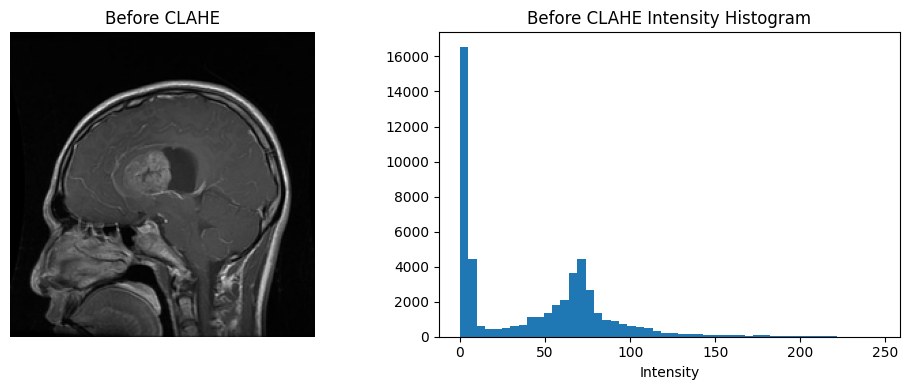

Before mean: 42.82 std: 40.78


In [8]:
import cv2
sample = train_clean.sample(1, random_state=SEED).iloc[0]
with Image.open(sample['path']) as im:
    before_img, _ = resize_with_padding(im)
before_arr = np.asarray(before_img)
before_gray = cv2.cvtColor(before_arr, cv2.COLOR_RGB2GRAY)

plt.figure(figsize=(10,4))
plt.subplot(1,2,1); plt.imshow(before_img); plt.title('Before CLAHE'); plt.axis('off')
plt.subplot(1,2,2); plt.hist(before_gray.ravel(), bins=50); plt.title('Before CLAHE Intensity Histogram'); plt.xlabel('Intensity')
plt.tight_layout(); plt.show()
print('Before mean:', round(float(before_gray.mean()),2), 'std:', round(float(before_gray.std()),2))

## Part 7 - Define CLAHE enhancement

In [9]:
import cv2

CLAHE_CLIP = 2.0
CLAHE_GRID = (8, 8)

def apply_clahe_rgb(pil_image):
    rgb = np.asarray(pil_image.convert('RGB'), dtype=np.uint8)
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=CLAHE_CLIP, tileGridSize=CLAHE_GRID)
    l2 = clahe.apply(l)
    enhanced = cv2.cvtColor(cv2.merge([l2, a, b]), cv2.COLOR_LAB2RGB)
    return Image.fromarray(enhanced)

## Part 8 - Apply CLAHE to Training and Testing

In [10]:
OUT = RESULTS / 'member3_clahe'
ENH_ROOT = OUT / 'enhanced_dataset'
OUT.mkdir(parents=True, exist_ok=True)

def enhance_split(df, split):
    rows=[]
    for n,row in enumerate(df.itertuples(index=False), start=1):
        src=Path(row.path)
        with Image.open(src) as im:
            resized,_ = resize_with_padding(im)
        enhanced=apply_clahe_rgb(resized)
        dst_dir=ENH_ROOT/split/row.class_name
        dst_dir.mkdir(parents=True, exist_ok=True)
        dst=dst_dir/f'{src.stem}.png'
        enhanced.save(dst)
        rows.append({'split':split,'class_name':row.class_name,'source_path':str(src),'output_path':str(dst)})
        if n%500==0: print(split, n, '/', len(df))
    return pd.DataFrame(rows)

train_clahe=enhance_split(train_clean,'Training')
test_clahe=enhance_split(test_clean,'Testing')
train_clahe.to_csv(OUT/'training_clahe_manifest.csv',index=False)
test_clahe.to_csv(OUT/'testing_clahe_manifest.csv',index=False)

Training 500 / 2713
Training 1000 / 2713
Training 1500 / 2713
Training 2000 / 2713
Training 2500 / 2713


## Part 9 - EDA AFTER CLAHE: visual and histogram comparison

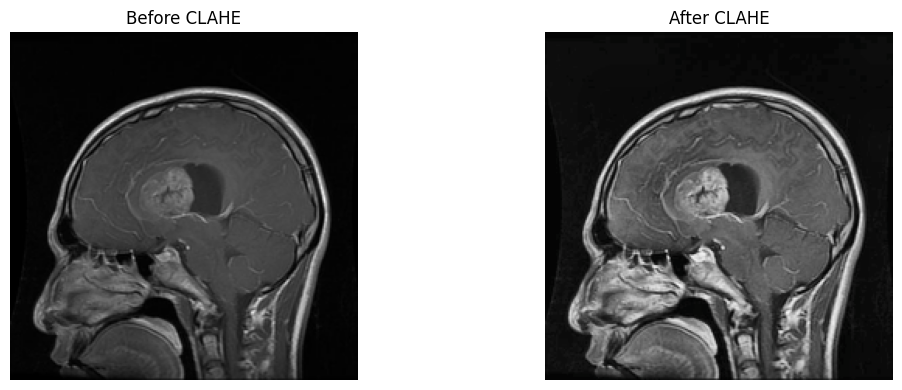

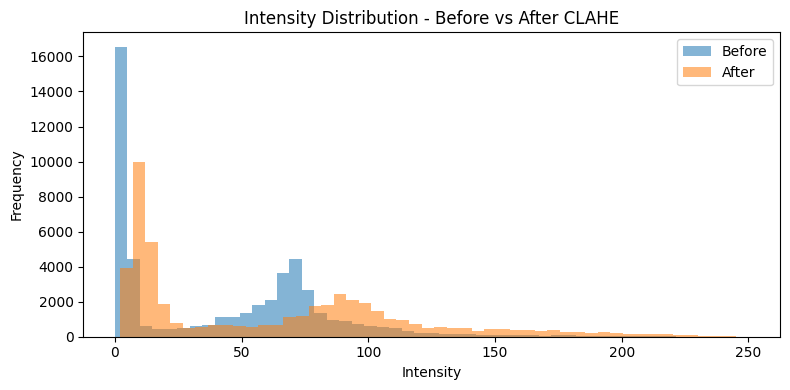

Before std: 40.78
After std : 54.87


In [11]:
after_img = apply_clahe_rgb(before_img)
after_gray = cv2.cvtColor(np.asarray(after_img), cv2.COLOR_RGB2GRAY)

plt.figure(figsize=(12,4))
plt.subplot(1,2,1); plt.imshow(before_img); plt.title('Before CLAHE'); plt.axis('off')
plt.subplot(1,2,2); plt.imshow(after_img); plt.title('After CLAHE'); plt.axis('off')
plt.tight_layout(); plt.show()

plt.figure(figsize=(8,4))
plt.hist(before_gray.ravel(), bins=50, alpha=0.55, label='Before')
plt.hist(after_gray.ravel(), bins=50, alpha=0.55, label='After')
plt.title('Intensity Distribution - Before vs After CLAHE')
plt.xlabel('Intensity'); plt.ylabel('Frequency'); plt.legend(); plt.tight_layout(); plt.show()

print('Before std:', round(float(before_gray.std()),2))
print('After std :', round(float(after_gray.std()),2))

## Part 10 - Download Member 3 outputs

In [12]:
def make_zip(folder, zip_path):
    folder = Path(folder)
    zip_path = Path(zip_path)
    if zip_path.exists():
        zip_path.unlink()
    shutil.make_archive(str(zip_path.with_suffix('')), 'zip', root_dir=folder)
    return zip_path

def download_file(path):
    try:
        from google.colab import files
        files.download(str(path))
    except Exception:
        print('Saved at:', path)

In [13]:
ZIP_OUT = make_zip(OUT, RESULTS/'Member3_CLAHE_Outputs.zip')
print('Created:', ZIP_OUT)
download_file(ZIP_OUT)

Created: /content/brain_tumor_preprocessing/results/Member3_CLAHE_Outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>